# Session 2 - Lab correction: build an autoencoder, then find out what it is worth

**DAT09-06 Representation Learning · Session 2 · Correction**

You are building the first piece of the assistant's memory: a map that turns a
product image into a handful of numbers, learned without a single label.

This is the worked correction of the lab. Every cell is filled in and executed,
and every checkpoint is followed by an answer. The cells that were yours to
write are marked **✏️ Solution**.

The numbers quoted in the answers are the ones printed in this notebook. Yours
will differ slightly in the third decimal place - different machines, same
conclusions.

To run it yourself: open it from inside the repository folder, after
`python data/prepare_data.py --fmnist`, and run the cells in order.

### Six checkpoints

| | What you produce |
|---|---|
| **1** | An autoencoder that trains, and proof it is not cheating |
| **2** | Where the bottleneck spends its budget, class by class |
| **3** | The four-number verdict, and the mistakes the probe makes |
| **4** | A representation wrecked by something irrelevant |
| **5** | The holes in the latent space |
| **6** | **The challenge** - best representation under a hard budget |

---

## 0 · Setup

If the first cell fails, you are not in the repository folder, or the
environment is not activated.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # make `common` importable

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from common.evaluation import compare_reports, evaluate_representation
from common.paths import PROCESSED, require
from common.plotting import PALETTE, use_course_style
from common.seeding import SEED, cpu_threads, set_seed

use_course_style()
set_seed(SEED)
cpu_threads()

print("torch", torch.__version__, "| device: cpu")

torch 2.13.0 | device: cpu


### 0.2 · The catalogue

Fashion-MNIST: 60,000 product photos, 28x28, grayscale.

The last 6,000 are held out. **Every number we report is computed on those**,
never on the images the model trained on. The labels are loaded too - and then
set aside. They are the ruler, not the training signal.

In [2]:
blob = np.load(require(PROCESSED / "fmnist_train.npz",
                       hint="python data/prepare_data.py --fmnist"))
images, labels = blob["images"], blob["labels"]
class_names = list(blob["classes"])

x = images.reshape(len(images), -1).astype(np.float32) / 255.0   # (60000, 784)

x_train_np, x_val_np = x[:54000], x[54000:]
y_train, y_val = labels[:54000], labels[54000:]

x_train = torch.from_numpy(x_train_np.copy())
x_val = torch.from_numpy(x_val_np.copy())

print(f"train {tuple(x_train.shape)}   val {tuple(x_val.shape)}")
print("classes:", ", ".join(class_names))

train (54000, 784)   val (6000, 784)
classes: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot


---

# Checkpoint 1 - Make it train, then prove it is not cheating

### 1.1 · The shape we are building

$$784 \;\xrightarrow{\;f_\phi\;}\; 256 \;\xrightarrow{\;\mathrm{ReLU}\;}\; d
\;\xrightarrow{\;g_\theta\;}\; 256 \;\xrightarrow{\;\mathrm{ReLU}\;}\; 784$$

Here is the **encoder**. It ends at $d$ with no activation: the code is
free to take any value.

In [3]:
def encoder_for(d, hidden=256):
    return nn.Sequential(
        nn.Linear(784, hidden),
        nn.ReLU(),
        nn.Linear(hidden, d),
    )


print(encoder_for(32))

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=32, bias=True)
)


### 1.2 ✏️ · The decoder is its mirror image

One difference: it ends with a **Sigmoid**, because our pixels live in
$[0, 1]$ and we want the output to live there too.

In [4]:
# ✏️ Solution
def decoder_for(d, hidden=256):
    return nn.Sequential(
        nn.Linear(d, hidden),
        nn.ReLU(),
        nn.Linear(hidden, 784),
        nn.Sigmoid(),
    )


print(decoder_for(32))

Sequential(
  (0): Linear(in_features=32, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=784, bias=True)
  (3): Sigmoid()
)


### 1.3 · Wrapping the two together

Note that `forward` returns **both** the reconstruction and the code -
you need $z$ in checkpoint 3, and running the encoder twice would be a waste.

In [5]:
class Autoencoder(nn.Module):
    """784 -> 256 -> d -> 256 -> 784."""

    def __init__(self, d: int, hidden: int = 256):
        super().__init__()
        self.d = d
        self.encoder = encoder_for(d, hidden)
        self.decoder = decoder_for(d, hidden)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

### 1.4 ✏️ · One training step

This is the heart of it, and it is four lines. Everything else in the training
loop is bookkeeping.

> **Watch out.** Forgetting `zero_grad()` makes gradients accumulate across
> batches. The loss still goes down, just worse, and nothing tells you. It is
> the most common silent bug in this course.

In [6]:
# ✏️ Solution
def one_step(model, x_batch, opt, loss_fn):
    """Forward, loss, backward, nudge. Returns the loss as a float."""
    x_hat, _ = model(x_batch)
    loss = loss_fn(x_hat, x_batch)      # the target IS the input
    opt.zero_grad()
    loss.backward()
    opt.step()
    return loss.item()

### 1.5 · The loop around it

Every model in this notebook is trained by this one function.

In [7]:
def train(model, data, *, epochs=8, batch=256, lr=1e-3, verbose=True):
    """Train an autoencoder on `data`, return the per-epoch loss history."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    n, history = len(data), []

    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n)
        running = 0.0

        for i in range(0, n, batch):
            x_batch = data[perm[i:i + batch]]
            running += one_step(model, x_batch, opt, loss_fn) * len(x_batch)

        history.append(running / n)
        if verbose:
            print(f"  epoch {epoch + 1:>2}/{epochs}   mse = {history[-1]:.5f}")

    return history

### 1.6 · Train one, and watch the loss fall

  epoch  1/8   mse = 0.04502
  epoch  2/8   mse = 0.02063
  epoch  3/8   mse = 0.01736
  epoch  4/8   mse = 0.01574
  epoch  5/8   mse = 0.01448
  epoch  6/8   mse = 0.01357
  epoch  7/8   mse = 0.01290
  epoch  8/8   mse = 0.01238


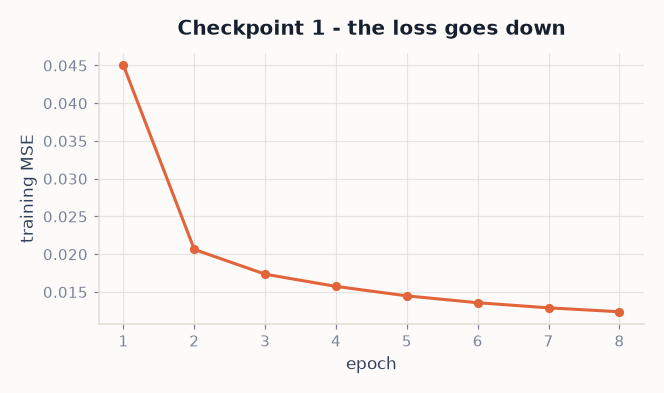

In [8]:
set_seed(SEED)
model32 = Autoencoder(d=32)
history = train(model32, x_train, epochs=8)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(range(1, len(history) + 1), history, marker="o", color=PALETTE["accent"])
ax.set_xlabel("epoch"); ax.set_ylabel("training MSE")
ax.set_title("Checkpoint 1 - the loss goes down")
plt.show()

### 1.7 ✏️ · Is that loss any good?

A number on its own means nothing. Before you can say your autoencoder works,
you need to know what a model that learned **nothing** would score.

The laziest possible model ignores its input and always outputs the **average
training image**. That is the ceiling of stupidity - your model has to be far
below it.

In [9]:
@torch.no_grad()
def val_mse(model):
    """Reconstruction MSE on the held-out products."""
    model.eval()
    x_hat, _ = model(x_val)
    return float(((x_hat.numpy() - x_val_np) ** 2).mean())


mean_image = x_train_np.mean(axis=0)

In [10]:
# ✏️ Solution
lazy_mse = float(((x_val_np - mean_image) ** 2).mean())

ours = val_mse(model32)
print(f"always-the-mean-image : {lazy_mse:.5f}")
print(f"our autoencoder d=32  : {ours:.5f}")
print(f"gap to zero closed    : {100 * (1 - ours / lazy_mse):.1f}%")

always-the-mean-image : 0.08730
our autoencoder d=32  : 0.01228
gap to zero closed    : 85.9%


### ❓ Checkpoint 1

1. Write down your three numbers. What percentage of the way from "always the
   mean image" to a perfect reconstruction did your model get?
2. Suppose I set `d = 784` and deleted both hidden layers, so the network is
   `Linear(784, 784)` then `Linear(784, 784)`. What validation MSE would you
   expect? **Why would that be bad news rather than good news?**
3. Your training loss is computed on images the model trained on. `val_mse` is
   not. Which of the two would you quote to someone deciding whether to use
   your encoder, and why?

**Answers**

1. Always the mean image: **0.0873**. Our autoencoder at $d = 32$: **0.0123**.
   It closes **85.9 %** of the gap between "always the mean image" and a perfect
   reconstruction.

2. Close to **zero**. Two `Linear(784, 784)` layers in a row can represent the
   identity exactly, so the network learns to copy its input and the error
   vanishes. That is bad news: nothing was compressed, the "code" *is* the image,
   and the model learned nothing about what products have in common. The
   bottleneck is what forces it to find structure. A low reconstruction error on
   its own is not evidence of a good representation.

3. `val_mse`. The training loss is measured on images the model has already
   seen, so a model that memorises scores well there and badly on anything new.
   Someone deciding whether to use the encoder cares about products it has never
   seen. Here the two are close (0.0124 on the last training epoch, 0.0123 on
   validation), so the model is not overfitting.

---

# Checkpoint 2 - Where the bottleneck spends its budget

### 2.1 · Four widths

In [11]:
DIMS = [2, 8, 32, 128]
models = {}

for d in DIMS:
    set_seed(SEED)                  # same start every time: a fair comparison
    models[d] = Autoencoder(d=d)
    train(models[d], x_train, epochs=8, verbose=False)
    print(f"d = {d:<4d} val mse = {val_mse(models[d]):.5f}")

d = 2    val mse = 0.03037
d = 8    val mse = 0.01591
d = 32   val mse = 0.01228
d = 128  val mse = 0.01087


### 2.2 ✏️ · Get the reconstructions out

`@torch.no_grad()` is not optional: without it PyTorch builds a gradient graph
for every pixel it draws, and `.numpy()` then refuses to convert a tensor that
still carries one.

In [12]:
# ✏️ Solution
@torch.no_grad()
def reconstruct(model, x):
    """Reconstructions as a numpy array of shape (n, 784)."""
    model.eval()
    x_hat, _ = model(x)
    return x_hat.numpy()


print(reconstruct(models[32], x_val[:4]).shape)   # expect (4, 784)

(4, 784)


### 2.3 · The same product at four widths

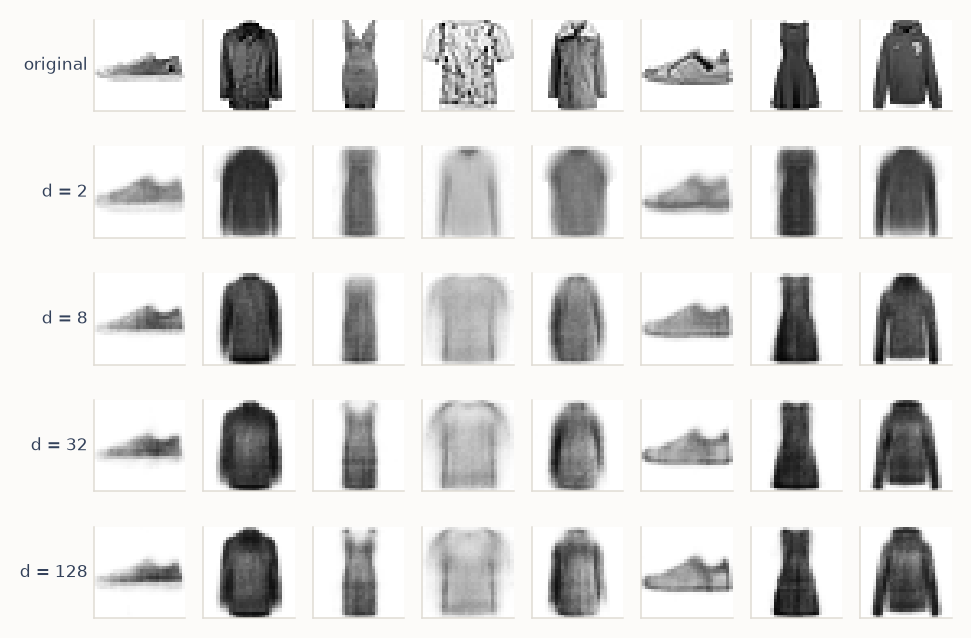

In [13]:
n_show = 8
rows = [("original", x_val_np[:n_show])] + [
    (f"d = {d}", reconstruct(models[d], x_val[:n_show])) for d in DIMS
]

fig, axes = plt.subplots(len(rows), n_show, figsize=(n_show * 1.1, len(rows) * 1.2),
                         squeeze=False)
for r, (label, grid) in enumerate(rows):
    for c in range(n_show):
        axes[r][c].imshow(1 - grid[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        axes[r][c].set_xticks([]); axes[r][c].set_yticks([])
    axes[r][0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=11)
fig.tight_layout()
plt.show()

### 2.4 ✏️ · Which products does it fail?

Looking at eight pictures is an anecdote. Measure it: the mean reconstruction
error **per class**, at the tightest and at a comfortable width.

This is where the labels earn their keep - not to train anything, only to slice
the error.

In [14]:
# ✏️ Solution
def per_class_mse(model, x_t, x_np, y):
    """Mean reconstruction MSE for each of the 10 classes."""
    err = ((reconstruct(model, x_t) - x_np) ** 2).mean(axis=1)
    return np.array([err[y == k].mean() for k in range(10)])


mse_2 = per_class_mse(models[2], x_val, x_val_np, y_val)
mse_32 = per_class_mse(models[32], x_val, x_val_np, y_val)
print(mse_2.round(4))

[0.0281 0.0202 0.031  0.0279 0.0297 0.0343 0.0282 0.0187 0.0524 0.0316]


### 2.5 · The chart

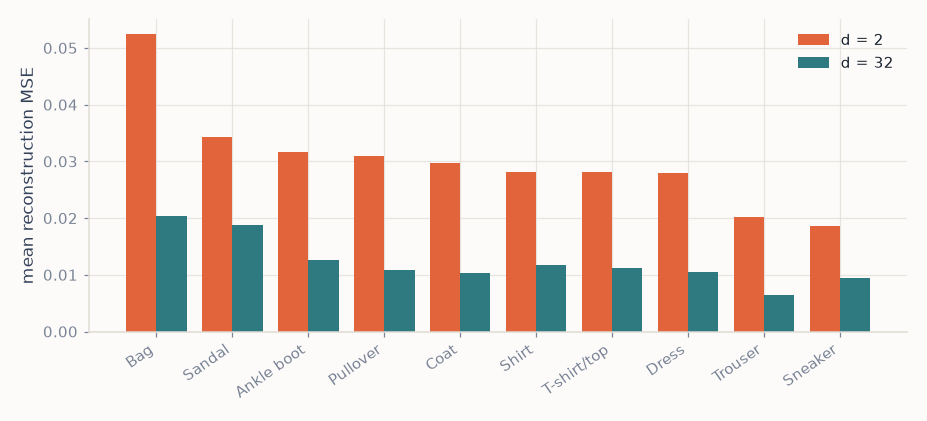

  Bag          d=2 0.0524   d=32 0.0203
  Sandal       d=2 0.0343   d=32 0.0189
  Ankle boot   d=2 0.0316   d=32 0.0127
  Pullover     d=2 0.0310   d=32 0.0109
  Coat         d=2 0.0297   d=32 0.0104
  Shirt        d=2 0.0282   d=32 0.0118
  T-shirt/top  d=2 0.0281   d=32 0.0112
  Dress        d=2 0.0279   d=32 0.0106
  Trouser      d=2 0.0202   d=32 0.0064
  Sneaker      d=2 0.0187   d=32 0.0094


In [15]:
order = np.argsort(-mse_2)
pos = np.arange(10)

fig, ax = plt.subplots(figsize=(8.4, 3.8))
ax.bar(pos - 0.2, mse_2[order], width=0.4, label="d = 2", color=PALETTE["accent"])
ax.bar(pos + 0.2, mse_32[order], width=0.4, label="d = 32", color=PALETTE["teal"])
ax.set_xticks(pos)
ax.set_xticklabels([class_names[k] for k in order], rotation=35, ha="right")
ax.set_ylabel("mean reconstruction MSE")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

for k in order:
    print(f"  {class_names[k]:<12s} d=2 {mse_2[k]:.4f}   d=32 {mse_32[k]:.4f}")

### ❓ Checkpoint 2

1. Which **three** classes are reconstructed worst at $d = 2$? Which three are
   reconstructed best? Look at the images in those classes - what do the hard
   ones have in common?
2. Going from $d = 2$ to $d = 32$, which class improves the **most**, in
   relative terms? Does that match what you saw in the picture grid?
3. The network was never told what a class is. Yet the error is clearly not
   spread evenly across them. **Where does that structure come from?**
4. At $d = 2$, find one product that comes back as a *different kind of
   product*. Which two classes get confused - and would a shopper make the same
   mistake?

**Answers**

1. Worst at $d = 2$: **Bag** (0.052), **Sandal** (0.034) and **Ankle boot**
   (0.032). Best: **Sneaker** (0.019), **Trouser** (0.020) and **Dress**
   (0.028). The hard classes are the *varied* ones: bags come in every shape,
   with or without handles, and sandals and boots are full of thin straps,
   heels and holes. The easy ones are near-identical silhouettes from one image
   to the next.

2. **Trouser**: its error is divided by 3.2 (-68 %), ahead of Coat and Pullover
   (-65 %). The picture grid cannot show it, because none of the eight products
   is a trouser. What the grid does show matches the next two: the coats and the
   pullover go from shapeless blobs at $d = 2$ to garments with collars, zips and
   sleeves at $d = 32$. Sandal and Sneaker improve the least (-45 % and -50 %).

3. From the **data**. A 2-number code has to spend its budget on whatever
   varies most across the whole catalogue - the overall silhouette: top, shoe,
   trousers, bag. Classes whose images all look alike are cheap to describe with
   that budget; classes with a lot of variety or fine detail are not. The labels
   were never used, but they are correlated with those pixel statistics, so the
   error lines up with them anyway.

4. The fifth product is a **Coat**: long sleeves, a collar, a zip. At $d = 2$
   it comes back as a plain grey top with **short sleeves** - a **T-shirt/top**.
   (The fourth, a short-sleeved printed Shirt, goes the other way and comes back
   as a pale long-sleeved top.) A shopper would never take a coat for a T-shirt:
   sleeve length is the first thing you see. With two numbers the model keeps
   little more than "a top, light or dark", and sleeves are a detail it cannot
   afford.

---

# Checkpoint 3 - The four-number verdict

A reconstruction you like the look of is not a result. This is.

> **train → freeze → probe → compare**

The encoder is already trained, and it never saw a label. Now we freeze it,
read off the codes, and only *then* bring the labels in - to measure.

| Baseline | Why it is the right one |
|---|---|
| **784 raw pixels** | no learning at all. If you cannot beat this, you learned nothing. |
| **PCA at the same $d$** | the same compression, done linearly. The honest bar. |

### First, all four on eight products

Before the real catalogue, the toy space from the slides: eight products with
**two** numbers each, so you can draw it. Four T-shirts at (1,1), (1,3), (3,1),
(3,3) and four ankle boots at (6,1), (6,3), (7,2) - plus **one boot at (2,2)**,
right in the middle of the T-shirts. The next cell shows the numbers
disagreeing about that one product.

probe      0.88
1-NN       0.38
silhouette 0.26
ARI        0.49

silhouette, product by product: [ 0.49  0.49  0.25  0.25 -0.68  0.41  0.41  0.49]
the stray boot is the negative one: it sits inside the wrong class.


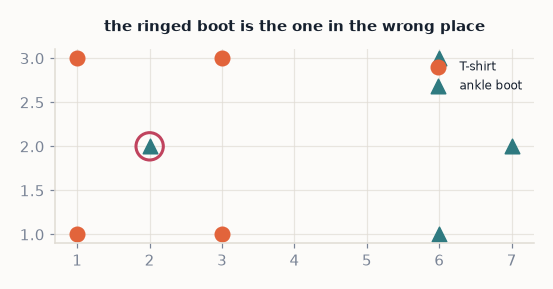

In [16]:
# The eight-product toy space from the slides.
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, silhouette_samples,
                             silhouette_score)

z_toy = np.array([[1., 1.], [1., 3.], [3., 1.], [3., 3.],     # T-shirts
                  [2., 2.], [6., 1.], [6., 3.], [7., 2.]])    # boots, (2,2) is the stray
y_toy = np.array([0, 0, 0, 0, 1, 1, 1, 1])                    # 0 = shirt, 1 = boot

# probe: one logistic regression on the codes
probe = LogisticRegression().fit(z_toy, y_toy).score(z_toy, y_toy)

# 1-NN, leave-one-out: each product's nearest OTHER product
dist = np.linalg.norm(z_toy[:, None] - z_toy[None], axis=-1) + np.eye(8) * 1e9
knn = (y_toy[dist.argmin(1)] == y_toy).mean()

# clustering, with the labels thrown away
C_toy = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(z_toy)

print(f"probe      {probe:.2f}")
print(f"1-NN       {knn:.2f}")
print(f"silhouette {silhouette_score(z_toy, y_toy):.2f}")
print(f"ARI        {adjusted_rand_score(y_toy, C_toy):.2f}")
print()
print("silhouette, product by product:", np.round(silhouette_samples(z_toy, y_toy), 2))
print("the stray boot is the negative one: it sits inside the wrong class.")

plt.figure(figsize=(5, 2.6))
for cls, marker, colour, name in [(0, "o", "#E2643B", "T-shirt"),
                                  (1, "^", "#2F7A80", "ankle boot")]:
    pts = z_toy[y_toy == cls]
    plt.scatter(pts[:, 0], pts[:, 1], marker=marker, c=colour, s=90, label=name)
plt.scatter(*z_toy[4], s=320, facecolors="none", edgecolors="#C0435E", linewidths=2)
plt.legend(loc="upper right", fontsize=8)
plt.title("the ringed boot is the one in the wrong place", fontsize=10)
plt.tight_layout()
plt.show()

The probe says 0.88 and 1-NN says 0.38, on the *same* eight codes. Neither is
wrong. The probe only needs one straight cut to work, while 1-NN is wrecked by a
single product in the wrong neighbourhood: that boot is wrong itself *and* drags
all four T-shirts down with it, because it is the nearest thing to every one of
them.

Keep that in mind when reading the table below.

### The four numbers, in full

Same numbering as the slides, so you can look them up. $z_i$ is product $i$'s
code, $y_i$ its true class, $d$ the width of the bottleneck.

| | metric | the question it asks | range |
|---|---|---|---|
| 1 | `probe_accuracy` | can one straight line read the classes? | 0 to 1 |
| 2 | `knn_accuracy` | are your neighbours your own kind? | 0 to 1 |
| 3 | `silhouette` | is there a gap between the classes? | $-1$ to $+1$ |
| 4 | `ari` | do two products land in the same group? | 0 to 1 |

The report also carries an `nmi` field. It scores the same clustering as `ari`,
in bits rather than in pairs. **We are not covering it today** - ignore the
column, or read up on normalised mutual information if you are curious.

**1 · `probe_accuracy`** - fit the single matrix $W$ (size $10 \times d$) that best
names 4,200 frozen codes, then measure the share of the other 1,800 it gets
right. Logistic regression and nothing more: it cannot learn a feature, so if it
succeeds, the codes already held the answer.

**2 · `knn_accuracy`** - no model is fitted at all. For each held-out code, take the
$k = 5$ nearest codes by straight-line distance and give it the class that wins
the vote. The share correct. *This is the one a retrieval system feels*, because
the assistant returns neighbours, not a classifier's output.

**3 · `silhouette`** - pure geometry, no labels used for fitting. For product $i$,
let $a_i$ be its mean distance to products of its own class and $b_i$ its mean
distance to those of the nearest other class. Then
$s_i = (b_i - a_i) / \max(a_i, b_i)$, and the silhouette is the average of $s_i$.
In $[-1, 1]$: 1 = deep inside its own class, 0 = sitting on the border.

**4 · `ari`** - run $k$-means (the standard clustering algorithm: give
it $k$, it hunts for $k$ groups of nearby points) with $k = 10$ and **no labels
at all**. It returns a grouping $C$; $Y$ is the truth. ARI scores $C$ against
$Y$: 0 for a random grouping, 1 for a perfect one.

It counts *pairs*. A pair of products is concordant when $C$ and $Y$ agree about
it - together in both, or apart in both. The Rand index RI is the share of
concordant pairs; because most pairs are apart in both, random groupings already
score high, so $\mathrm{ARI} = (\mathrm{RI} - \mathbb{E}[\mathrm{RI}]) /
(1 - \mathbb{E}[\mathrm{RI}])$, where $\mathbb{E}[\mathrm{RI}]$ is what chance gives.

### 3.1 ✏️ · Read the codes off the frozen encoder

In [17]:
# ✏️ Solution
@torch.no_grad()
def encode(model, x):
    """The frozen codes z, as a numpy array of shape (n, d)."""
    model.eval()
    return model.encoder(x).numpy()


codes = {d: encode(models[d], x_val) for d in DIMS}
for d, z in codes.items():
    print(f"d = {d:<4d} -> z {z.shape}")

d = 2    -> z (6000, 2)
d = 8    -> z (6000, 8)
d = 32   -> z (6000, 32)
d = 128  -> z (6000, 128)


### 3.2 ✏️ · The two baselines

`evaluate_representation(z, y, name=..., verbose=False)` computes all four
numbers at once and returns one report. Every remaining session of the course
uses it.

In [18]:
# ✏️ Solution
from sklearn.decomposition import PCA

raw = evaluate_representation(x_val_np, y_val, name="raw pixels", verbose=False)

pca = PCA(n_components=32, random_state=SEED).fit(x_train_np)
pca_rep = evaluate_representation(pca.transform(x_val_np), y_val,
                                  name="PCA d=32", verbose=False)

print(raw.probe_accuracy, pca_rep.probe_accuracy)

0.8027777777777778 0.8105555555555556


### 3.3 · The table

In [19]:
reports = [raw, pca_rep] + [
    evaluate_representation(codes[d], y_val, name=f"autoencoder d={d}", verbose=False)
    for d in DIMS
]

table = compare_reports(reports)
table

,dim,probe_accuracy,knn_accuracy,nmi,ari,silhouette,n_train,n_test
name,,,,,,,,
autoencoder d=128,128,0.8256,0.8272,0.5405,0.3609,0.0732,4200,1800
autoencoder d=32,32,0.8172,0.8189,0.5258,0.3302,0.0801,4200,1800
PCA d=32,32,0.8106,0.8111,0.5345,0.3592,0.0690,4200,1800
raw pixels,784,0.8028,0.7856,0.5338,0.3866,0.0455,4200,1800
autoencoder d=8,8,0.7489,0.8067,0.5472,0.3481,0.0880,4200,1800
autoencoder d=2,2,0.6028,0.5944,0.5354,0.3775,0.0725,4200,1800


### 3.4 ✏️ · What mistakes does the probe make?

`probe_accuracy` is one number hiding ten classes. Fit the same probe yourself
and look at **which** classes it confuses - that tells you what the
representation failed to separate.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

z = codes[32]
cut = 4200                                   # same split the course helper uses
scaler = StandardScaler().fit(z[:cut])
clf = LogisticRegression(max_iter=1000, random_state=SEED)
clf.fit(scaler.transform(z[:cut]), y_val[:cut])

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [21]:
# ✏️ Solution
pred = clf.predict(scaler.transform(z[cut:]))
cm = confusion_matrix(y_val[cut:], pred, normalize="true")

### 3.5 · Draw it

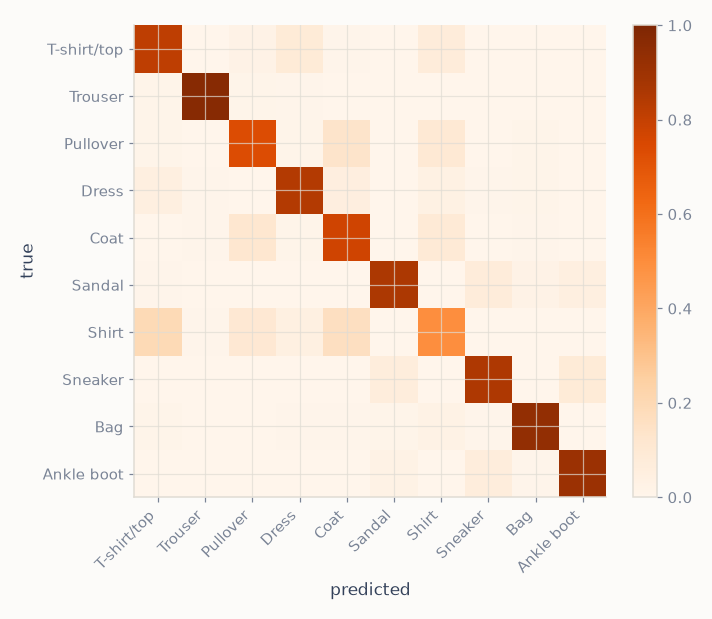

worst confusion: Shirt predicted as T-shirt/top (19% of the time)


In [22]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(cm, cmap="Oranges", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.colorbar(im, fraction=0.046)
fig.tight_layout()
plt.show()

off = cm - np.diag(np.diag(cm))
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"worst confusion: {class_names[i]} predicted as {class_names[j]} "
      f"({off[i, j]:.0%} of the time)")

### ❓ Checkpoint 3

1. Which representations beat **raw pixels** on `probe_accuracy`? On
   `knn_accuracy`? **Are they the same ones?**
2. The autoencoder at $d = 8$ uses **98x fewer numbers** than raw pixels. How
   does it do on $k$-NN - and why is that the number a retrieval system cares
   about more than `probe_accuracy`?
3. For $d = 32$, compare `probe_accuracy` and `silhouette`. One is around 0.81,
   the other around 0.08. **Both are correct.** What is each telling you that
   the other is not? Name one product feature you could *not* build on this
   space despite the 0.81.
4. Look at the `ari` column. It comes from running $k$-means with the labels
   hidden and then checking how well the clusters line up with the truth.
   **Does any autoencoder beat raw pixels on it?** Reconcile that with $d = 32$
   clearly winning on $k$-NN - what are the two numbers measuring that makes
   them disagree?
5. What is the worst confusion in your matrix? Is it the same pair of classes
   that checkpoint 2 said was hardest to reconstruct? If not - what does that
   disagreement tell you about reconstruction error as a guide?
6. Going from $d = 32$ to $d = 128$ quadruples your storage bill. What did it
   buy? Which $d$ would you ship, and what would you need to know about the
   product to be sure?

**Answers**

1. On `probe_accuracy` (raw pixels: 0.803): the autoencoders at $d = 128$
   (0.826) and $d = 32$ (0.817), and PCA at $d = 32$ (0.811). On `knn_accuracy`
   (raw pixels: 0.786): the same three, **plus the autoencoder at $d = 8$**
   (0.807). So no, they are not the same: $d = 8$ loses to raw pixels on the
   probe and beats them on $k$-NN.

2. 784 / 8 = 98 times fewer numbers, and its $k$-NN accuracy is **0.807**,
   higher than raw pixels (0.786). Retrieval is the number that matters because
   the assistant returns *neighbours*: "show me products like this one" is a
   nearest-neighbour search, and nobody trains a classifier on top. The probe
   asks whether the classes can be cut apart by straight lines, which 8
   dimensions do less well (0.749) even though the neighbourhoods are good.

3. `probe_accuracy` = 0.817 says the classes can be **separated by
   hyperplanes**: there is a linear cut that gets most products right.
   `silhouette` = 0.080 says there is **no gap** between them: a product is barely
   closer to its own class than to the nearest other class, so the classes touch
   and the borders are crowded. Something you could not build on this space:
   anything that relies on distances alone to decide "same kind or not" - for
   example, discovering the categories automatically by clustering, or a
   distance threshold that keeps "similar products" inside the same category.

4. **No.** Raw pixels have the highest ARI (0.387); the best autoencoder is
   $d = 2$ at 0.378, and $d = 32$ only gets 0.330. $k$-NN is **local**: it only
   asks whether the five closest products are of the right kind. ARI is
   **global**: $k$-means must carve the whole space into ten compact groups that
   match the classes. With classes that touch (low silhouette), and shirts,
   T-shirts, pullovers and coats that blend into one another, $k$-means draws its
   borders elsewhere. Good neighbourhoods do not imply well-separated clusters.

5. **Shirt predicted as T-shirt/top**, 19 % of the time (Shirt is also confused
   with Coat and Pullover). That is not what checkpoint 2 called hardest: Bag
   was the worst to reconstruct, yet its row in the matrix is one of the
   darkest on the diagonal: the probe has no trouble recognising bags.
   Reconstruction error measures how hard an image is to *redraw pixel by pixel*,
   not how hard it is to tell apart from other classes. It is a poor guide to
   what the representation fails to separate.

6. Very little: +0.008 on the probe (0.817 to 0.826), +0.008 on $k$-NN (0.819
   to 0.827), a lower MSE (0.0123 to 0.0109), and a *lower* silhouette (0.080 to
   0.073). Four times the storage for less than one point. **Ship $d = 32$** -
   or even $d = 8$ if the product is retrieval only ($k$-NN 0.807). To be sure,
   you would need to know which metric the product actually depends on, how big
   the catalogue is (storage and search latency), and whether one point of
   $k$-NN is something users would notice.

---

# Checkpoint 4 - Wreck it with something irrelevant

**The most important part of the lab.**

Real catalogue photos are not clean. Suppliers shoot under different lighting,
some images carry a watermark, some have a coloured corner. None of that says
anything about the product.

| | Nuisance | What it stands for |
|---|---|---|
| **A** | a 12x12 square of random brightness in the corner | a watermark, a badge, a supplier sticker |
| **B** | the whole image multiplied by a random factor in $[0.25, 1]$ | inconsistent studio lighting |

Neither one carries **any** information about the class. A perfect
representation would ignore them entirely.

### 4.1 · The two nuisances

In [23]:
def add_patch(arr, rng, side=12):
    """Nuisance A: a constant-brightness square in the corner of each image."""
    out = arr.reshape(-1, 28, 28).copy()
    v = rng.uniform(0.0, 1.0, size=len(out)).astype(np.float32)
    out[:, 0:side, 0:side] = v[:, None, None]
    return out.reshape(len(out), -1)


def relight(arr, rng, lo=0.25, hi=1.0):
    """Nuisance B: every pixel of an image scaled by one random factor."""
    v = rng.uniform(lo, hi, size=len(arr)).astype(np.float32)
    return np.clip(arr * v[:, None], 0.0, 1.0)


NUISANCES = {"A - corner patch": add_patch, "B - lighting": relight}

### 4.2 · What they look like

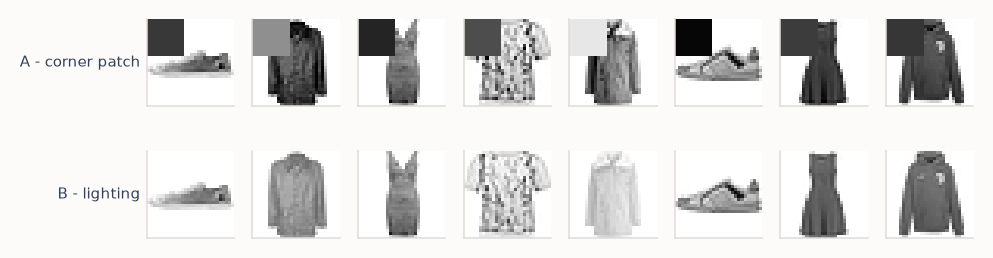

In [24]:
fig, axes = plt.subplots(2, 8, figsize=(9, 2.8))
for r, (name, fn) in enumerate(NUISANCES.items()):
    shown = fn(x_val_np[:8], np.random.default_rng(SEED))
    for c in range(8):
        axes[r][c].imshow(1 - shown[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        axes[r][c].set_xticks([]); axes[r][c].set_yticks([])
    axes[r][0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
fig.tight_layout()
plt.show()

### 4.3 ✏️ · Train on a corrupted catalogue

**Nothing changes** except the data: same architecture, same epochs, same
seed.

In [25]:
# ✏️ Solution
def run_on(train_np, val_np, d):
    """Train from scratch on `train_np`; measure on `val_np`. Returns 3 numbers."""
    set_seed(SEED)
    m = Autoencoder(d=d)
    train(m, torch.from_numpy(train_np.copy()), epochs=8, verbose=False)
    val_t = torch.from_numpy(val_np.copy())
    rep = evaluate_representation(encode(m, val_t), y_val, name="x", verbose=False)
    mse = float(((reconstruct(m, val_t) - val_np) ** 2).mean())
    return rep.probe_accuracy, rep.knn_accuracy, mse


print(run_on(x_train_np, x_val_np, 8))   # sanity check: close to the clean row

(0.7488888888888889, 0.8066666666666666, 0.01590951532125473)


### 4.4 · Six models

In [26]:
import pandas as pd

rows = []
for d in (2, 8, 32):
    clean = evaluate_representation(codes[d], y_val, name="clean", verbose=False)
    rows.append({"d": d, "data": "clean", "probe": clean.probe_accuracy,
                 "knn": clean.knn_accuracy, "val mse": val_mse(models[d])})

    for name, fn in NUISANCES.items():
        tr = fn(x_train_np, np.random.default_rng(SEED))
        va = fn(x_val_np, np.random.default_rng(SEED + 1))
        probe, knn, mse = run_on(tr, va, d)
        rows.append({"d": d, "data": name, "probe": probe, "knn": knn,
                     "val mse": mse})

pd.DataFrame(rows).round(4)

,d,data,probe,knn,val mse
0,2,clean,0.6028,0.5944,0.0304
1,2,A - corner patch,0.4300,0.5228,0.0366
2,2,B - lighting,0.4928,0.5489,0.0150
3,8,clean,0.7489,0.8067,0.0159
4,8,A - corner patch,0.7228,0.7556,0.0150
5,8,B - lighting,0.7289,0.7633,0.0079
6,32,clean,0.8172,0.8189,0.0123
7,32,A - corner patch,0.8022,0.7789,0.0110
8,32,B - lighting,0.8006,0.7939,0.0065


### ❓ Checkpoint 4 - the questions that matter most today

1. Write out your table. At $d = 2$, how many points of `probe_accuracy` did
   the **corner patch** cost you? Express it as a share of the gap between the
   clean score and random guessing (0.10).
2. Now read the **`val mse` column** at $d = 8$ and $d = 32$. Compare the clean
   row to the two nuisance rows. **Which has the lower reconstruction error?**
3. That result should bother you. The models trained on corrupted data report a
   *better* loss and a *worse* representation. Give the explanation - and in
   doing so, answer this: **are those three MSE numbers even comparable?** What
   changed between them besides the model?
4. The nuisances carry no information about the product. Explain in two
   sentences why the encoder spends capacity on them anyway. *(What is the loss
   actually rewarded for? How many of the 784 pixels does a 12x12 square
   occupy?)*
5. Why is the damage much worse at $d = 2$ than at $d = 32$? What does that
   suggest about choosing $d$ when your real data is messy?
6. You must choose between two encoders for the assistant and all you are given
   is their reconstruction losses. **Write one sentence saying why that is not
   enough**, citing two numbers from your own table.
7. Name one thing you could change - in the data, the architecture or the loss
   - to make the encoder stop caring about the lighting. You do not have to
   implement it.

**Answers**

1. At $d = 2$ the probe falls from **0.603** (clean) to **0.430** with the
   corner patch: **17.3 points** lost. The gap between the clean score and
   random guessing is 0.603 - 0.10 = 0.503, so the patch wipes out **34 %** of
   what the model had learned above chance.

   |  | clean | A - corner patch | B - lighting |
   |---|---|---|---|
   | $d = 2$ probe / knn | 0.603 / 0.594 | 0.430 / 0.523 | 0.493 / 0.549 |
   | $d = 8$ probe / knn | 0.749 / 0.807 | 0.723 / 0.756 | 0.729 / 0.763 |
   | $d = 32$ probe / knn | 0.817 / 0.819 | 0.802 / 0.779 | 0.801 / 0.794 |

2. The **nuisance rows**. At $d = 8$: clean 0.0159, patch 0.0150, lighting
   **0.0079**. At $d = 32$: clean 0.0123, patch 0.0110, lighting **0.0065**.

3. The three MSE numbers are **not comparable**: each one is measured on a
   *different validation set*, so the target changed along with the model.
   Lighting multiplies every image by a factor between 0.25 and 1. Darker images
   have smaller pixel values, so the same relative mistake gives a smaller
   squared error. The patch adds 144 pixels of one constant value, which are easy
   to reconstruct from a single number and pull the average error over 784 pixels
   down. A better loss on easier targets says nothing about the representation -
   and the representation got worse.

4. The loss rewards reconstructing **every pixel equally**, and the encoder has
   no idea which pixels are "about the product". A 12x12 square is 144 / 784 =
   **18 %** of the image, and its brightness is a single random number that
   explains a lot of pixel error, so encoding it is one of the cheapest ways to
   reduce the loss. Lighting is the same: one factor that touches all 784 pixels.

5. At $d = 2$, giving one number to the patch spends **half the budget** on
   noise. At $d = 32$, spending one or two dimensions on it still leaves thirty.
   That is why the patch costs 17 probe points at $d = 2$ and less than 2 at
   $d = 32$. With messy real data, do not pick the tightest $d$ that works on
   clean data: leave some margin, and test the encoder against the nuisances you
   expect.

6. At $d = 32$, the encoder trained under varying lighting has *half* the
   reconstruction error of the clean one (0.0065 vs 0.0123) and a **worse**
   $k$-NN accuracy (0.794 vs 0.819), so ranking encoders by reconstruction loss
   can put them in exactly the wrong order.

7. Any of these: **augment** the training data - feed the encoder a randomly
   relit image and ask it to reconstruct the original, so lighting becomes noise
   to undo rather than information to keep; **normalise** each image's brightness
   before encoding it, so the factor never reaches the encoder; or change the
   objective so that two lightings of the same product must get the same code -
   which is the idea behind contrastive learning, later in the course.

---

# Checkpoint 5 - Find the hole

The latent space is good at *describing* products. Now try to *move around in
it*. Nothing in our loss ever said anything about the space **between** two
products.

### 5.1 · A decoder you can call directly

In [27]:
@torch.no_grad()
def decode(model, z):
    model.eval()
    return model.decoder(torch.as_tensor(z, dtype=torch.float32)).numpy()


z32 = codes[32]
print(f"real codes: mean {z32.mean():+.2f}, std {z32.std():.2f}, "
      f"range [{z32.min():.1f}, {z32.max():.1f}]")

real codes: mean -0.01, std 3.37, range [-16.1, 12.6]


### 5.2 ✏️ · Decode eight points that are not products

The fairest possible test: draw them from a Gaussian with exactly the same
per-dimension mean and standard deviation as the real codes.

In [28]:
# ✏️ Solution
rng = np.random.default_rng(SEED)
z_random = rng.normal(z32.mean(0), z32.std(0), size=(8, 32)).astype(np.float32)
fakes = decode(models[32], z_random)

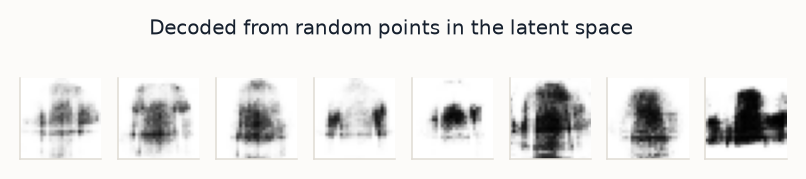

In [29]:
fig, axes = plt.subplots(1, 8, figsize=(9, 1.4))
for c, ax in enumerate(axes):
    ax.imshow(1 - fakes[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Decoded from random points in the latent space", y=1.14)
plt.show()

### 5.3 ✏️ · Walk from one product to another

The point at fraction $t$ on the straight line between two codes is
$(1 - t)\,z_a + t\,z_b$.

In [30]:
# ✏️ Solution
a, b = 0, 3                                  # two validation products
alphas = np.linspace(0, 1, 9)
walk = decode(models[32], np.stack([(1 - t) * z32[a] + t * z32[b] for t in alphas]))

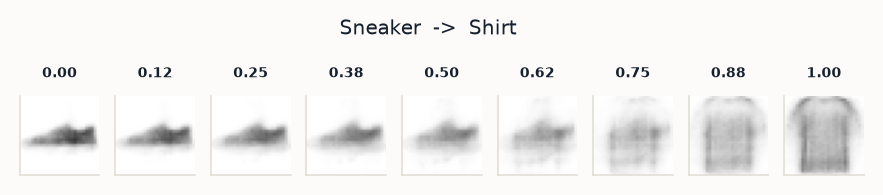

In [31]:
fig, axes = plt.subplots(1, len(alphas), figsize=(len(alphas) * 1.1, 1.5))
for c, ax in enumerate(axes):
    ax.imshow(1 - walk[c].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{alphas[c]:.2f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"{class_names[y_val[a]]}  ->  {class_names[y_val[b]]}", y=1.2)
plt.show()

### ❓ Checkpoint 5

1. Are the random decodings **products**? Describe what you actually see.
2. In the walk, look at $t \approx 0.5$. Is it a plausible garment, or
   something else?
3. Our objective asked for exactly one thing. Write it in a sentence - then
   write what it **never asked for**, which is why this fails.
4. In one sentence: what extra instruction would you add to the loss so a
   random point decodes to something sensible?

**Answers**

1. No. They are blurry smudges: a vague top-like outline in some of them,
   mottled texture, dark patches, nothing you could name or sell.

2. Not a garment. At $t \approx 0.5$ you see a faded sneaker with the faint
   outline of a shirt over it: a **cross-fade** of two images, not a product
   halfway between the two.

3. The objective asked for one thing: **reconstruct each training image from
   its own code**. It never asked anything about the codes *in between* - the
   points that no real product maps to. The decoder was only ever trained where
   real codes land; everywhere else its output is unconstrained, so random points
   and midpoints decode to whatever happens to come out.

4. Add a term that pushes the codes to follow a known, simple distribution
   (for example a standard Gaussian), so that a point drawn from that
   distribution falls where the decoder has been trained. That is what the
   variational autoencoder does.

---

# Checkpoint 6 - The challenge

**Open-ended.**

> Build the best representation you can under a hard budget:
> **$d \leq 16$**, and **no more than 60 seconds of training** on your own
> machine. Maximise **`knn_accuracy`** on the clean validation set.

The reference to beat is a plain `Autoencoder(d=16)` trained for 8 epochs. It
scores about **0.82** in a few seconds. An hour of careful work gets you to
roughly **0.83** - the gains are small, which is exactly why *which lever moved
it* is the interesting answer, not the number.

| Lever | Try |
|---|---|
| epochs / learning rate | more epochs in the same 60 s; `lr` 3e-4 to 3e-3 |
| width and depth | wider hidden layer, or two hidden layers |
| activation | `ReLU`, `GELU`, `Tanh` |
| corruption | add noise to the input, keep the clean target |
| the loss | `L1Loss` instead of `MSELoss` |

**The rules.** Time only the training. Keep a row for **every** configuration,
including the ones that lose. One change at a time, or you cannot tell which
lever did it.

### 6.1 · The harness

In [32]:
import time

results = []


def attempt(name, model, *, epochs, noise=0.0, lr=1e-3):
    """Train under the clock, evaluate, record the row."""
    set_seed(SEED)
    t0 = time.time()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    n = len(x_train)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, 256):
            clean = x_train[perm[i:i + 256]]
            inp = torch.clamp(clean + noise * torch.randn_like(clean), 0, 1) if noise else clean
            x_hat, _ = model(inp)
            loss = loss_fn(x_hat, clean)
            opt.zero_grad(); loss.backward(); opt.step()
    secs = time.time() - t0
    rep = evaluate_representation(encode(model, x_val), y_val, name=name, verbose=False)
    results.append({"config": name, "d": model.d, "seconds": round(secs, 1),
                    "knn": rep.knn_accuracy, "probe": rep.probe_accuracy})
    print(f"  {name:<30s} {secs:5.1f}s   knn={rep.knn_accuracy:.4f}  "
          f"probe={rep.probe_accuracy:.4f}")
    return rep


attempt("reference: d=16, 8 epochs", Autoencoder(d=16), epochs=8);

  reference: d=16, 8 epochs        2.0s   knn=0.8194  probe=0.7983


### 6.2 ✏️ · Three attempts

One `attempt(...)` call per configuration, each changing **one thing** against
the reference: more epochs, then a wider hidden layer on top, then input noise
instead of the wider layer.

In [33]:
# ✏️ Solution
attempt("d=16, 20 epochs", Autoencoder(d=16), epochs=20)
attempt("d=16, 20 ep, hidden 512", Autoencoder(d=16, hidden=512), epochs=20)
attempt("d=16, 20 ep, noise 0.3", Autoencoder(d=16), epochs=20, noise=0.3);

  d=16, 20 epochs                  4.9s   knn=0.8256  probe=0.7983
  d=16, 20 ep, hidden 512          7.8s   knn=0.8333  probe=0.8017
  d=16, 20 ep, noise 0.3          10.8s   knn=0.8106  probe=0.7889


In [34]:
import pandas as pd

pd.DataFrame(results).sort_values("knn", ascending=False)

,config,d,seconds,knn,probe
2,"d=16, 20 ep, hidden 512",16,7.8,0.833333,0.801667
1,"d=16, 20 epochs",16,4.9,0.825556,0.798333
0,"reference: d=16, 8 epochs",16,2.0,0.819444,0.798333
3,"d=16, 20 ep, noise 0.3",16,10.8,0.810556,0.788889


### ❓ Checkpoint 6

1. Your best `knn_accuracy` under the budget, and the configuration that got
   it.
2. **Which single lever mattered most?** How do you know - which two rows of
   your table prove it?
3. Did anything you expected to help actually hurt? Why do you think that is?
4. Your best model has $d \leq 16$. How does it compare to the $d = 32$ and
   $d = 128$ models from checkpoint 3? What does that say about how much the
   *width* of the bottleneck really mattered?

**Answers**

1. **0.833**, with `d=16, 20 ep, hidden 512`, trained in under 8 seconds - well
   inside the 60-second budget.

2. The **wider hidden layer**: going from `d=16, 20 epochs` (0.826) to
   `d=16, 20 ep, hidden 512` (0.833) is the largest single step, +0.8 points.
   More epochs gave +0.6 (reference 0.819 to 0.826). These differences are
   small, though: with 1,800 test products, one point is about 18 products. To
   be sure which lever matters, you would rerun each configuration with several
   seeds.

3. **Input noise** hurt: 0.811 against 0.826 for the same 20 epochs without
   it. A standard deviation of 0.3 is large for pixels in $[0, 1]$: it drowns
   the fine details that distinguish close neighbours, and the encoder spends
   its capacity undoing the noise. A smaller noise level, or longer training,
   might turn it into a gain.

4. It beats both: 0.833 against 0.819 for $d = 32$ and 0.827 for $d = 128$
   (checkpoint 3, 8 epochs, hidden 256). Beyond about 16 dimensions, the width
   of the bottleneck was not what limited the representation: the training budget
   and the capacity of the layers around it mattered more.

---

## What you built today

- An encoder that turns a product into a handful of numbers, trained **without
  a single label**.
- The measurement loop - **train, freeze, probe, compare** - that every
  remaining session of this course runs on.
- Direct evidence that **reconstruction loss is not a proxy for usefulness**:
  two nuisances that carry no information made the loss look *better* and the
  representation measurably *worse*.
- A latent space that reads well and travels badly.

**Friday:** the variational autoencoder, which closes the holes you found in
checkpoint 5.